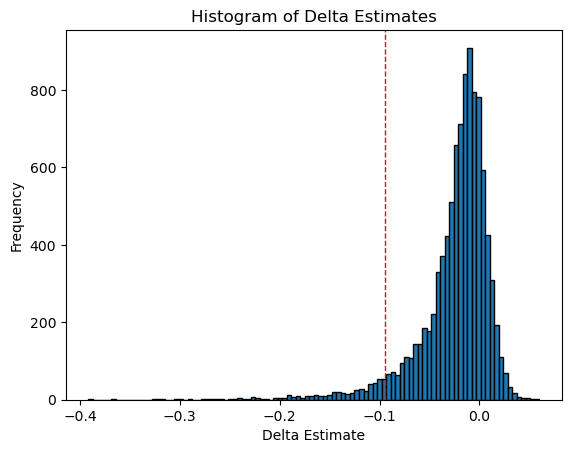

5th Percentile Critical Value: -0.09451714152615927
Mean of Delta Estimates: -0.025061064979765426


In [9]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Parameters
mu = 0.25
n_burn = 150
n_sample = 75
n = n_burn + n_sample
n_iter = 10000
delta_hat = []

np.random.seed(123)  # For reproducibility

# Monte Carlo Simulation
for _ in range(n_iter):
  
    eps = np.random.normal(0, 1, n)

    y = np.zeros(n)
    for t in range(1, n):
        y[t] = mu + y[t-1] + eps[t]

    y = y[n_burn:]
  
    Delta_y = np.diff(y)
    lag_y = y[:-1]
  
    X = sm.add_constant(lag_y)
    model = sm.OLS(Delta_y, X).fit()
    delta_hat.append(model.params[1])

cv_5perct = np.percentile(delta_hat, 5)

# Display the distribution, critical value, and mean
plt.hist(delta_hat, bins=100, edgecolor='k')
plt.axvline(x=cv_5perct, color='red', linestyle='dashed', linewidth=1)
plt.title('Histogram of Delta Estimates')
plt.xlabel('Delta Estimate')
plt.ylabel('Frequency')
plt.show()

print(f"5th Percentile Critical Value: {cv_5perct}")
print(f"Mean of Delta Estimates: {np.mean(delta_hat)}")